# MELD: Clasificación de emociones por texto con Prompt Engineering (LLM + Few‑shot + RAG)

Este notebook resuelve **MELD** (Emotion Recognition in Conversations) como un problema de **clasificación de emociones** a partir de texto.
La idea principal es **no entrenar** un clasificador, sino hacer *prompt engineering* sobre un **modelo LLM instruct** y mejorar resultados con:

- **Prompt “estricto”** (etiqueta única + definiciones)
- **Contexto conversacional** (ventana de turnos previos)
- **Few‑shot** (ejemplos dentro del prompt)
- **RAG ligero**: recuperar ejemplos similares del *train* con embeddings y usarlos como few‑shot
- (Opcional) **votación / self‑consistency** con varias muestras

> Requisitos: una GPU de ~16GB suele ser suficiente cargando un modelo 7B/8B en **4‑bit** (bitsandbytes).  
> Si no tienes GPU, funcionará en CPU pero mucho más lento.


## 1) Instalación y setup

Si estás en Colab / entorno limpio, ejecuta esta celda.


In [1]:
#Librerias necesarias
%pip -q install -U transformers accelerate bitsandbytes sentence-transformers scikit-learn pandas matplotlib kagglehub

import os, re, random
from pathlib import Path
import numpy as np
import pandas as pd

import torch
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Mejor rendimiento en Ampere+ (si tu GPU soporta bfloat16)
DTYPE = torch.bfloat16 if torch.cuda.is_available() and torch.cuda.is_bf16_supported() else torch.float16
print("CUDA:", torch.cuda.is_available(), "| dtype:", DTYPE)



[notice] A new release of pip is available: 25.1.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
CUDA: True | dtype: torch.bfloat16


## 2) Descargar / cargar MELD

Usamos `kagglehub` para descargar o cargar el dataset de meld.


In [2]:
import kagglehub

# Descarga (requiere que Kaggle esté configurado en tu entorno; en Colab suele ser necesario subir kaggle.json)
DATA_DIR = kagglehub.dataset_download("zaber666/meld-dataset")
DATA_DIR = Path(DATA_DIR)
print("Dataset en:", DATA_DIR)

# Buscar archivos esperados (por si cambian subcarpetas)
def find_one(pattern: str) -> Path:
    hits = list(DATA_DIR.glob(pattern))
    if len(hits) == 0:
        hits = list(DATA_DIR.glob("**/" + pattern))
    if len(hits) == 0:
        raise FileNotFoundError(f"No encuentro {pattern} dentro de {DATA_DIR}")
    return hits[0]

train_path = find_one("train_sent_emo.csv")
dev_path   = find_one("dev_sent_emo.csv")
test_path  = find_one("test_sent_emo.csv")

print("train:", train_path)
print("dev  :", dev_path)
print("test :", test_path)

train_raw = pd.read_csv(train_path, encoding="utf-8")
dev_raw   = pd.read_csv(dev_path, encoding="utf-8")
test_raw  = pd.read_csv(test_path, encoding="utf-8")

train_raw.head()


C:\Users\Haojie\Desktop\MacOS\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset en: C:\Users\Haojie\.cache\kagglehub\datasets\zaber666\meld-dataset\versions\1
train: C:\Users\Haojie\.cache\kagglehub\datasets\zaber666\meld-dataset\versions\1\MELD-RAW\MELD.Raw\train\train_sent_emo.csv
dev  : C:\Users\Haojie\.cache\kagglehub\datasets\zaber666\meld-dataset\versions\1\MELD-RAW\MELD.Raw\dev_sent_emo.csv
test : C:\Users\Haojie\.cache\kagglehub\datasets\zaber666\meld-dataset\versions\1\MELD-RAW\MELD.Raw\test_sent_emo.csv


,Sr No.,Utterance,Speaker,Emotion,Sentiment,Dialogue_ID,Utterance_ID,Season,Episode,StartTime,EndTime
0,1,also I was the point person on my companys tr...,Chandler,neutral,neutral,0,0,8,21,"00:16:16,059","00:16:21,731"
1,2,You mustve had your hands full.,The Interviewer,neutral,neutral,0,1,8,21,"00:16:21,940","00:16:23,442"
2,3,That I did. That I did.,Chandler,neutral,neutral,0,2,8,21,"00:16:23,442","00:16:26,389"
3,4,So lets talk a little bit about your duties.,The Interviewer,neutral,neutral,0,3,8,21,"00:16:26,820","00:16:29,572"
4,5,My duties? All right.,Chandler,surprise,positive,0,4,8,21,"00:16:34,452","00:16:40,917"


## 3) Preprocesado: contexto conversacional + normalización de hablantes

MELD tiene `Dialogue_ID`, `Utterance_ID`, `Speaker`, `Utterance` y `Emotion`.  
Creamos una ventana de *N* turnos previos como contexto (por defecto `WINDOW=2`) y normalizamos hablantes por diálogo (`SPEAKER_0`, `SPEAKER_1`…).


In [3]:
# Parámetros de contexto
WINDOW = 2  # nº de turnos previos a incluir
MAX_CONTEXT_CHARS = 900  # recorta contexto largo para no inflar el prompt

def clean_text(s: str) -> str:
    if not isinstance(s, str):
        return ""
    # algunos dumps llevan apóstrofo raro 0x92
    s = s.replace("\x92", "'")
    s = re.sub(r"\s+", " ", s).strip()
    return s

def normalize_speakers(df: pd.DataFrame) -> pd.DataFrame:
    # Mapea Speaker -> SPEAKER_k dentro de cada Dialogue_ID
    df = df.copy()
    df["Speaker"] = df["Speaker"].astype(str).map(clean_text)
    norm = []
    for _, g in df.groupby("Dialogue_ID", sort=False):
        speakers = {}
        next_id = 0
        for spk in g["Speaker"].tolist():
            if spk not in speakers:
                speakers[spk] = f"SPEAKER_{next_id}"
                next_id += 1
        norm.extend([speakers[spk] for spk in g["Speaker"].tolist()])
    df["Speaker_N"] = norm
    return df

def build_context_rows(df: pd.DataFrame, split_name: str) -> pd.DataFrame:
    df = df.copy()
    df["split"] = split_name
    # Kaggle MELD suele traer: Dialogue_ID, Utterance_ID, Speaker, Utterance, Emotion, Sentiment
    for col in ["Dialogue_ID", "Utterance_ID", "Speaker", "Utterance", "Emotion"]:
        if col not in df.columns:
            raise KeyError(f"Falta columna {col}. Columnas disponibles: {df.columns.tolist()}")
    df["Utterance"] = df["Utterance"].map(clean_text)
    df["Emotion"] = df["Emotion"].astype(str).map(lambda x: clean_text(x).lower())

    df = df.sort_values(["Dialogue_ID", "Utterance_ID"]).reset_index(drop=True)
    df = normalize_speakers(df)

    # construir contexto
    contexts = []
    current_turns = []
    for _, g in df.groupby("Dialogue_ID", sort=False):
        utts = g["Utterance"].tolist()
        spks = g["Speaker_N"].tolist()
        for i in range(len(g)):
            start = max(0, i - WINDOW)
            ctx_lines = [f"{spks[j]}: {utts[j]}" for j in range(start, i)]
            ctx = "\n".join(ctx_lines).strip()
            if len(ctx) > MAX_CONTEXT_CHARS:
                ctx = ctx[-MAX_CONTEXT_CHARS:]  # recorte por la izquierda
            contexts.append(ctx)
            current_turns.append(f"{spks[i]}: {utts[i]}")

    df_out = pd.DataFrame({
        "split": df["split"].values,
        "dialogue_id": df["Dialogue_ID"].values,
        "utterance_id": df["Utterance_ID"].values,
        "speaker": df["Speaker_N"].values,
        "utterance": df["Utterance"].values,
        "emotion": df["Emotion"].values,
        "context": contexts,
        "current_turn": current_turns
    })
    return df_out

train_df = build_context_rows(train_raw, "train")
dev_df   = build_context_rows(dev_raw, "dev")
test_df  = build_context_rows(test_raw, "test")

print("train/dev/test:", len(train_df), len(dev_df), len(test_df))
train_df.head()


train/dev/test: 9989 1109 2610


,split,dialogue_id,utterance_id,speaker,utterance,emotion,context,current_turn
0,train,0,0,SPEAKER_0,also I was the point person on my company's tr...,neutral,,SPEAKER_0: also I was the point person on my c...
1,train,0,1,SPEAKER_1,You must've had your hands full.,neutral,SPEAKER_0: also I was the point person on my c...,SPEAKER_1: You must've had your hands full.
2,train,0,2,SPEAKER_0,That I did. That I did.,neutral,SPEAKER_0: also I was the point person on my c...,SPEAKER_0: That I did. That I did.
3,train,0,3,SPEAKER_1,So let's talk a little bit about your duties.,neutral,SPEAKER_1: You must've had your hands full.\nS...,SPEAKER_1: So let's talk a little bit about yo...
4,train,0,4,SPEAKER_0,My duties? All right.,surprise,SPEAKER_0: That I did. That I did.\nSPEAKER_1:...,SPEAKER_0: My duties? All right.


## 4) Labels y validación rápida de clases

MELD voy a aplicar estas 7 emociones:
`anger, disgust, fear, joy, neutral, sadness, surprise`


In [4]:
LABELS = ["anger", "disgust", "fear", "joy", "neutral", "sadness", "surprise"]

all_labels = sorted(set(train_df["emotion"]) | set(dev_df["emotion"]) | set(test_df["emotion"]))
print("Etiquetas encontradas:", all_labels)

unknown = [x for x in all_labels if x not in LABELS]
if unknown:
    print("⚠️ Etiquetas no esperadas:", unknown)

train_df["emotion"].value_counts()


Etiquetas encontradas: ['anger', 'disgust', 'fear', 'joy', 'neutral', 'sadness', 'surprise']


emotion
neutral     4710
joy         1743
surprise    1205
anger       1109
sadness      683
disgust      271
fear         268
Name: count, dtype: int64

## 5) Cargar un LLM instruct (7B/8B) en 4‑bit

Recomendados (buenos para clasificación por prompt):
- `mistralai/Mistral-7B-Instruct-v0.3`
- `meta-llama/Meta-Llama-3.1-8B-Instruct` (requiere aceptar licencia en HF)
- `Qwen/Qwen2.5-7B-Instruct` (suele ir muy bien)



In [5]:
from transformers import AutoTokenizer, AutoModelForCausalLM, GenerationConfig

MODEL_NAME = "Qwen/Qwen2.5-7B-Instruct"

# Carga 4-bit (bitsandbytes)
bnb_config = dict(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=DTYPE,
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    device_map="auto",
    torch_dtype=DTYPE,
    **bnb_config,
)

# Configuración de generación (clasificación -> respuesta corta, determinista)
gen_cfg = GenerationConfig(
    max_new_tokens=8,
    do_sample=False,
    temperature=0.0,
    top_p=1.0,
    repetition_penalty=1.0,
)

print("Modelo cargado en:", next(model.parameters()).device)


`torch_dtype` is deprecated! Use `dtype` instead!
The `load_in_4bit` and `load_in_8bit` arguments are deprecated and will be removed in the future versions. Please, pass a `BitsAndBytesConfig` object in `quantization_config` argument instead.
Loading checkpoint shards: 100%|██████████| 4/4 [00:17<00:00,  4.27s/it]
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Modelo cargado en: cuda:0


## 6) Prompt base (estricto) + parseo robusto

Clave para mejorar:
- pedir **una sola etiqueta** y **nada más**
- dar **definiciones** breves de cada emoción
- instrucción de desempate: si hay duda -> `neutral`


In [6]:
EMOTION_DEFS = {
    "anger":    "anger, irritation, frustration, hostility",
    "disgust":  "disgust, repulsion, strong rejection",
    "fear":     "fear, anxiety, intense worry, feeling threatened",
    "joy":      "joy, enthusiasm, satisfaction, positive humor",
    "neutral":  "no strong emotion, informational/normal tone",
    "sadness":  "sadness, sorrow, disappointment, discouragement",
    "surprise": "surprise, shock, disbelief, unexpected reaction",
}

SYSTEM_PROMPT = (
    "You are an emotion classifier for dialogue turns.\n"
    "You must choose EXACTLY ONE label from the list and output ONLY the label.\n"
    f"Labels: {', '.join(LABELS)}.\n\n"
    "Quick definitions:\n" +
    "\n".join([f"- {k}: {v}" for k, v in EMOTION_DEFS.items()]) +
    "\n\nRule: if it is not clear, answer 'neutral'."
)

def build_user_prompt(context: str, current_turn: str) -> str:
    context = (context or "").strip()
    if context:
        return (
            "Previous context:\n"
            f"{context}\n\n"
            "Current turn:\n"
            f"{current_turn}\n\n"
            "What is the emotion of the current turn? Answer ONLY with the label."
        )
    else:
        return (
            "Current turn:\n"
            f"{current_turn}\n\n"
            "What is the emotion of the current turn? Answer ONLY with the label."
        )

def make_chat_input(system_prompt: str, user_prompt: str) -> str:
    # Use the chat template if supported; otherwise fall back to plain text
    if hasattr(tokenizer, "apply_chat_template") and getattr(tokenizer, "chat_template", None):
        messages = [
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": user_prompt},
        ]
        return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    return f"[SYSTEM]\n{system_prompt}\n\n[USER]\n{user_prompt}\n\n[ASSISTANT]\n"

LABEL_RE = re.compile(r"(anger|disgust|fear|joy|neutral|sadness|surprise)", re.IGNORECASE)

def parse_label(text: str) -> str:
    t = (text or "").strip().lower()
    t = re.sub(r"[^a-z\s]", " ", t)
    t = re.sub(r"\s+", " ", t).strip()
    m = LABEL_RE.search(t)
    if m:
        return m.group(1).lower()
    return "neutral"

@torch.inference_mode()
def predict_one(context: str, current_turn: str) -> str:
    user_prompt = build_user_prompt(context, current_turn)
    prompt = make_chat_input(SYSTEM_PROMPT, user_prompt)
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    out = model.generate(**inputs, generation_config=gen_cfg)
    gen = tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
    return parse_label(gen)

# sanity check
row = dev_df.sample(1, random_state=SEED).iloc[0]
print("GT:", row["emotion"])
print("Pred:", predict_one(row["context"], row["current_turn"]))
print("\nTurn:\n", row["current_turn"])
print("\nContext:\n", row["context"])


GT: neutral
Pred: surprise

Turn:
 SPEAKER_2: Hi, sorry I'm late, I couldn't find my bearings.

Context:
 SPEAKER_1: Mom already called this morning to remind me not to wear my hair up. Did you know my ears are not my best feature?
SPEAKER_0: Some days it's all I can think about.


## 7) Evaluación (rápida) en un subconjunto

Ajusta `EVAL_N_DEV` y `EVAL_N_TEST` según tiempo.


In [7]:
from tqdm.auto import tqdm

EVAL_N_DEV  = 600   # para probar prompts rápido
EVAL_N_TEST = 1200   # evaluación más seria (sube si tienes tiempo)

def eval_df(df: pd.DataFrame, n: int, title: str):
    sub = df.sample(n=min(n, len(df)), random_state=SEED).reset_index(drop=True)
    y_true = sub["emotion"].tolist()
    y_pred = []
    for _, r in tqdm(sub.iterrows(), total=len(sub), desc=title):
        y_pred.append(predict_one(r["context"], r["current_turn"]))
    print("accuracy:", accuracy_score(y_true, y_pred))
    print("macro f1:", f1_score(y_true, y_pred, average="macro"))
    print("weighted f1:", f1_score(y_true, y_pred, average="weighted"))
    print("\n", classification_report(y_true, y_pred, labels=LABELS, zero_division=0))
    return y_true, y_pred

y_true_dev, y_pred_dev = eval_df(dev_df, EVAL_N_DEV, "DEV baseline")


DEV baseline: 100%|██████████| 600/600 [04:37<00:00,  2.16it/s]

accuracy: 0.5683333333333334
macro f1: 0.45953305925731414
weighted f1: 0.5687721617622851

               precision    recall  f1-score   support

       anger       0.65      0.31      0.42        78
     disgust       0.15      0.62      0.24        16
        fear       0.67      0.19      0.30        21
         joy       0.63      0.43      0.51        88
     neutral       0.66      0.75      0.71       253
     sadness       0.61      0.46      0.53        65
    surprise       0.47      0.57      0.52        79

    accuracy                           0.57       600
   macro avg       0.55      0.48      0.46       600
weighted avg       0.61      0.57      0.57       600



### Matriz de confusión (DEV)

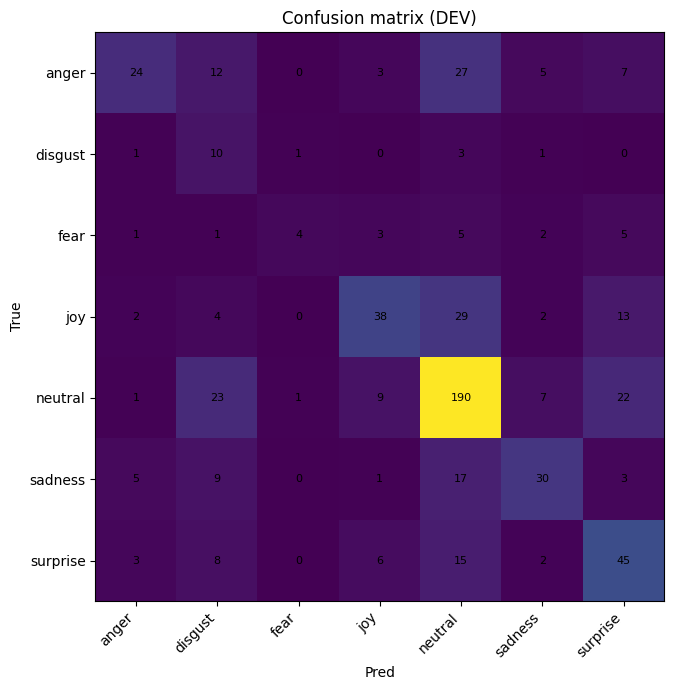

In [8]:
cm = confusion_matrix(y_true_dev, y_pred_dev, labels=LABELS)

plt.figure(figsize=(7, 7))
plt.imshow(cm)
plt.xticks(range(len(LABELS)), LABELS, rotation=45, ha="right")
plt.yticks(range(len(LABELS)), LABELS)
plt.title("Confusion matrix (DEV)")
plt.xlabel("Pred")
plt.ylabel("True")
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=8)
plt.tight_layout()
plt.show()


## 8) Prompt engineering avanzado: Few‑shot con recuperación (RAG ligero)

Estrategia:
1. Calculamos embeddings de ejemplos del *train* (texto = `context + current_turn`)
2. Para cada ejemplo a predecir, recuperamos los `K` más similares
3. Metemos esos ejemplos como **few‑shot** dentro del prompt


In [9]:
from sentence_transformers import SentenceTransformer
from sklearn.neighbors import NearestNeighbors

def row_text_from_parts(context: str, current_turn: str) -> str:
    context = (context or "").strip()
    if context:
        return context + "\n" + current_turn
    return current_turn

# Para acelerar: indexar una muestra del train (sube TRAIN_INDEX_N si quieres)
TRAIN_INDEX_N = min(6000, len(train_df))
train_index = train_df.sample(n=TRAIN_INDEX_N, random_state=SEED).reset_index(drop=True)

embed_model_name = "sentence-transformers/all-MiniLM-L6-v2"
embedder = SentenceTransformer(embed_model_name, device="cuda" if torch.cuda.is_available() else "cpu")

train_texts = [row_text_from_parts(r["context"], r["current_turn"]) for _, r in train_index.iterrows()]
train_emb = embedder.encode(train_texts, batch_size=64, show_progress_bar=True, normalize_embeddings=True)

knn = NearestNeighbors(n_neighbors=6, metric="cosine")
knn.fit(train_emb)

def retrieve_fewshot(context: str, current_turn: str, k: int = 4):
    q = row_text_from_parts(context, current_turn)
    q_emb = embedder.encode([q], normalize_embeddings=True)
    _, idxs = knn.kneighbors(q_emb, n_neighbors=min(k, len(train_index)))
    shots = []
    for idx in idxs[0]:
        rr = train_index.iloc[int(idx)]
        shots.append((rr["context"], rr["current_turn"], rr["emotion"]))
    return shots

def build_user_prompt_rag(context: str, current_turn: str, shots, k: int = 4) -> str:
    ex_blocks = []
    for i, (ctx_i, turn_i, y_i) in enumerate(shots[:k], start=1):
        if (ctx_i or "").strip():
            ex = f"Ejemplo {i}\nContexto:\n{ctx_i}\nTurno:\n{turn_i}\nEtiqueta: {y_i}\n"
        else:
            ex = f"Ejemplo {i}\nTurno:\n{turn_i}\nEtiqueta: {y_i}\n"
        ex_blocks.append(ex)
    ex_text = "\n".join(ex_blocks).strip()

    base = build_user_prompt(context, current_turn)
    return (
        "Usa estos ejemplos como guía (few-shot):\n\n"
        f"{ex_text}\n\n"
        "Ahora clasifica el siguiente caso:\n\n"
        f"{base}"
    )

@torch.inference_mode()
def predict_one_rag(context: str, current_turn: str, k: int = 4) -> str:
    shots = retrieve_fewshot(context, current_turn, k=k)
    user_prompt = build_user_prompt_rag(context, current_turn, shots, k=k)
    prompt = make_chat_input(SYSTEM_PROMPT, user_prompt)
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    out = model.generate(**inputs, generation_config=gen_cfg)
    gen = tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
    return parse_label(gen)

# sanity check
row = dev_df.sample(1, random_state=SEED+1).iloc[0]
print("GT:", row["emotion"])
print("Pred (RAG):", predict_one_rag(row["context"], row["current_turn"], k=4))


Batches: 100%|██████████| 94/94 [00:02<00:00, 43.84it/s]


GT: neutral
Pred (RAG): neutral


## 9) Evaluar RAG few‑shot en DEV y TEST

In [10]:
from tqdm.auto import tqdm

def eval_df_rag(df: pd.DataFrame, n: int, title: str, k: int = 4):
    sub = df.sample(n=min(n, len(df)), random_state=SEED).reset_index(drop=True)
    y_true = sub["emotion"].tolist()
    y_pred = []
    for _, r in tqdm(sub.iterrows(), total=len(sub), desc=title):
        y_pred.append(predict_one_rag(r["context"], r["current_turn"], k=k))
    print("accuracy:", accuracy_score(y_true, y_pred))
    print("macro f1:", f1_score(y_true, y_pred, average="macro"))
    print("weighted f1:", f1_score(y_true, y_pred, average="weighted"))
    print("\n", classification_report(y_true, y_pred, labels=LABELS, zero_division=0))
    return y_true, y_pred

y_true_dev_rag, y_pred_dev_rag = eval_df_rag(dev_df, EVAL_N_DEV, "DEV RAG few-shot", k=4)


DEV RAG few-shot: 100%|██████████| 600/600 [04:49<00:00,  2.07it/s]

accuracy: 0.5533333333333333
macro f1: 0.4453869593337397
weighted f1: 0.5395668881076774

               precision    recall  f1-score   support

       anger       0.65      0.28      0.39        78
     disgust       0.16      0.75      0.26        16
        fear       0.86      0.29      0.43        21
         joy       0.71      0.27      0.39        88
     neutral       0.61      0.83      0.70       253
     sadness       0.59      0.40      0.48        65
    surprise       0.51      0.42      0.46        79

    accuracy                           0.55       600
   macro avg       0.58      0.46      0.45       600
weighted avg       0.61      0.55      0.54       600



In [11]:
# Evaluación en TEST (subconjunto; sube EVAL_N_TEST si quieres)
y_true_test_rag, y_pred_test_rag = eval_df_rag(test_df, EVAL_N_TEST, "TEST RAG few-shot", k=4)


TEST RAG few-shot: 100%|██████████| 1200/1200 [09:49<00:00,  2.04it/s]

accuracy: 0.5658333333333333
macro f1: 0.3741168476543167
weighted f1: 0.5566681276679203

               precision    recall  f1-score   support

       anger       0.57      0.21      0.31       164
     disgust       0.11      0.58      0.19        31
        fear       0.08      0.07      0.07        15
         joy       0.65      0.37      0.47       171
     neutral       0.67      0.82      0.74       580
     sadness       0.57      0.30      0.39       104
    surprise       0.50      0.39      0.44       135

    accuracy                           0.57      1200
   macro avg       0.45      0.39      0.37      1200
weighted avg       0.61      0.57      0.56      1200



## 10) (Opcional) Self‑consistency / votación

Genera 3–5 muestras con temperatura baja y haz mayoría.
Suele subir macro‑F1 un poco, a cambio de tiempo.


In [16]:
from collections import Counter
from copy import deepcopy

gen_cfg_sample = deepcopy(gen_cfg)
gen_cfg_sample.do_sample = True
gen_cfg_sample.temperature = 0.4
gen_cfg_sample.top_p = 0.9

@torch.inference_mode()
def predict_one_rag_vote(context: str, current_turn: str, k: int = 4, n_votes: int = 3) -> str:
    shots = retrieve_fewshot(context, current_turn, k=k)
    user_prompt = build_user_prompt_rag(context, current_turn, shots, k=k)
    prompt = make_chat_input(SYSTEM_PROMPT, user_prompt)
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    preds = []
    for _ in range(n_votes):
        out = model.generate(**inputs, generation_config=gen_cfg_sample)
        gen = tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
        preds.append(parse_label(gen))

    return Counter(preds).most_common(1)[0][0]

# Ejemplo
row = dev_df.sample(1, random_state=SEED).iloc[0]
print("GT:", row["emotion"])
print("Pred vote:", predict_one_rag_vote(row["context"], row["current_turn"], k=4, n_votes=3))


GT: neutral
Pred vote: neutral


## Notas y tips para subir rendimiento

- **Cambia el modelo**: a menudo un 8B instruct sube bastante frente a FLAN‑T5 para MELD.
- Sube `WINDOW` si el prompt no se hace demasiado largo.
- Sube `TRAIN_INDEX_N` y/o `k` para RAG few-shot (cuidado: prompts muy largos empeoran).
- Si el modelo “explica” demasiado, endurece: “responde SOLO con una de estas palabras”.
- Exporta predicciones a CSV para analizar errores por clase (*fear*/*disgust* suelen ser difíciles).

